## Imports

In [36]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np 
from scipy.stats import f_oneway, ttest_ind #(not in environment yet?)
import sys

## Loading Data
Loading one single datafile using pandas, concatenatin all data files into one big table to analyse together

## Looping over all datafiles and concatenating them

In [37]:
# how can I concatenate all files within a certain folder path without loading a single file first

behav_data_path = "/mnt/home/bielefeldt/MPIB-SRT/879-multieyetem/behavioural_outputfiles"
sys.path.append(behav_data_path)

df_list = []
for file_name in os.listdir(behav_data_path):
    if file_name.endswith(".txt") and "pr.txt" not in file_name and not file_name.startswith("resultfile_pil"):  # Check if the file has .txt extension
        file_path = os.path.join(behav_data_path, file_name)
  
        # Read the file and determine whether to skip rows based on numerical content
        data = pd.read_table(file_path, skipinitialspace=True)
        has_numerical_content = data.applymap(lambda x: isinstance(x, (int, float))).any(axis=1)
        
        # Exclude rows with no numerical content
        data = data[has_numerical_content]
        
        df_list.append(data)

# Concatenate all DataFrames in the list
df = pd.concat(df_list, ignore_index=True)

In [38]:
## Descriptive Statistics

# not sure if any of the following is actually helpful, df.describe probably is but seemed weird because not all columns were included
print(df.head(11))
pd.DataFrame.describe(df)
df_description = df.describe()
print(df_description)

              task_version         date   subID sub_gender  sub_age  \
0   MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
1   MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
2   MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
3   MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
4   MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
5   MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
6   MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
7   MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
8   MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
9   MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
10  MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   

    block_number  trial           object_1_name  object_1_id  object_1_rot  \
0              1      1       01_lighthouse.jpg            1         

In [39]:
df.info

<bound method DataFrame.info of                  task_version         date   subID sub_gender  sub_age  \
0      MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
1      MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
2      MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
3      MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
4      MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
...                       ...          ...     ...        ...      ...   
16699  MultiEyeTem_version_01  04-Apr-2023  30K8XE          F       27   
16700  MultiEyeTem_version_01  04-Apr-2023  30K8XE          F       27   
16701  MultiEyeTem_version_01  04-Apr-2023  30K8XE          F       27   
16702  MultiEyeTem_version_01  04-Apr-2023  30K8XE          F       27   
16703  MultiEyeTem_version_01  04-Apr-2023  30K8XE          F       27   

       block_number  trial              object_1_name  object_1_id  \
0        

## Confidence / Manipulation Checks

In [40]:
# check wether the mask makes a difference (would be a problem if it did)

# check wether condition makes it harder (it should)

# checking accuracy between upright and upside-down might also count as a manipulation check

# generally check if accuracy is good enough (when is it significantly above chance?)

## Accuracy Tests

In [41]:
## Mask vs no Mask

# accuracy data mask
# there is no mask vs. no mask column yet, probably needs to be added individually

# mask_data = df.loc[df['XX'] == 1, 'acc_trial_concrete_cued']
# nomask_data = df.loc[df['XX'] == 1, 'acc_trial_concrete_cued']

# # Perform two-sample independent t-test
# t_statistic, p_value = ttest_ind(mask_data, nomask_data)

# # Define the significance level (alpha)
# alpha = 0.05

# # Print the t-test results
# print("T-Test Results:")
# print("T-statistic:", t_statistic)
# print("p-value:", p_value)

# # Check if the p-value is less than alpha to determine significance
# if p_value < alpha:
#     print("The t-test indicates a significant difference in accuracy between upright and upside-down probe items.")
# else:
#     print("The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.")


## accuracy for position of item within the load conditions (mnemonic distance?, in position two and three they should be remembered better)


## accuracy depending on the orientation, (oblique bias?)
# could bin the orientations into 4 


# I have this line (except the .values at the end) underneath in the obliaue effect stuff
mean_per_ori = df.groupby('object_cued_rot')['acc_trial_concrete_cued'].mean().values

# what is this? once object cued and the other items, probably copied from underneath and wanted to adapt this to 
# check for the orientation of all 16 orientations individually?? Is that necessary though?
acc_ori1 = df.loc[df['object_cued_rot'] == 1, 'acc_trial_concrete_cued']
acc_cond2 = df.loc[df['items_presented'] == 2, 'acc_trial_concrete_cued']
acc_cond3 = df.loc[df['items_presented'] == 3, 'acc_trial_concrete_cued']

## Oblique Effect

two categories (oblique vs cardinal)

object_cued_rot
11.25     0.769376
33.75     0.743516
56.25     0.696854
78.75     0.731299
101.25    0.725775
123.75    0.673624
146.25    0.682629
168.75    0.732569
191.25    0.723282
213.75    0.700661
236.25    0.684667
258.75    0.706717
281.25    0.741063
303.75    0.676015
326.25    0.707574
348.75    0.790087
Name: acc_trial_concrete_cued, dtype: float64
mean per category:  Cardinal_Category
Cardinal    0.739966
Oblique     0.695657
Name: acc_trial_concrete_cued, dtype: float64
grouped data: object_cued_rot  Cardinal_Category
11.25            Cardinal             0.769376
33.75            Oblique              0.743516
56.25            Oblique              0.696854
78.75            Cardinal             0.731299
101.25           Cardinal             0.725775
123.75           Oblique              0.673624
146.25           Oblique              0.682629
168.75           Cardinal             0.732569
191.25           Cardinal             0.723282
213.75           Oblique            

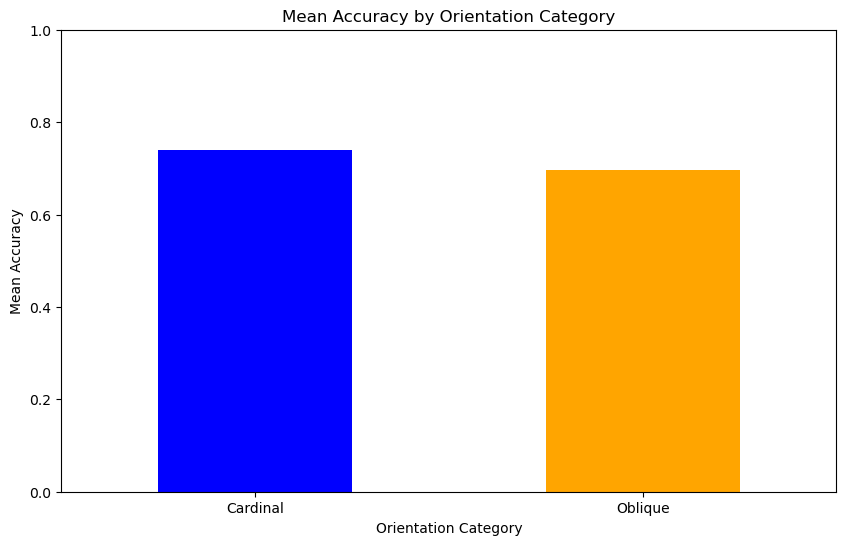

T-Test Results:
T-statistic: 3.553596492782577
p-value: 0.0031781472965880875
The t-test indicates a significant difference in accuracy between cardinal and oblique orientations in probe items.


In [42]:
## Grouping and comparing the data according to two categories: cardinal (8 orientations closest to the cardinal axes) and oblique (remaining 8 diagonal orientations)

mean_per_ori = df.groupby('object_cued_rot')['acc_trial_concrete_cued'].mean()
print(mean_per_ori)

# orientations closest to the cardinal axes
orientation_subset_cardinal = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]

# Create a new column to indicate the categories
df['Cardinal_Category'] = df['object_cued_rot'].apply(lambda x: 'Cardinal' if x in orientation_subset_cardinal else 'Oblique')

# Calculate mean accuracy for each category
mean_per_category = df.groupby('Cardinal_Category')['acc_trial_concrete_cued'].mean()
print("mean per category: ", mean_per_category)

# Group data by 'object_cued_rot' and 'Cardinal_Category'
grouped_cardinal = df.groupby(['object_cued_rot', 'Cardinal_Category'])['acc_trial_concrete_cued'].mean()

print("grouped data:", grouped_cardinal)

# Reset index for easier formatting
grouped_cardinal = grouped_cardinal.reset_index()

# Organize data by 'Cardinal' and 'Oblique' categories
cardinal_data = grouped_cardinal[grouped_cardinal['Cardinal_Category'] == 'Cardinal']
oblique_data = grouped_cardinal[grouped_cardinal['Cardinal_Category'] == 'Oblique']



# # Select data for 'Cardinal' category

# # Select data for 'Oblique' category
# oblique_data = df.loc[df['Cardinal_Category'] == 'Oblique', 'acc_trial_concrete_cued']

cardinal_acc = cardinal_data['acc_trial_concrete_cued']
oblique_acc = oblique_data['acc_trial_concrete_cued']

## Visualising the data 

mean_per_category
# Create a bar plot using matplotlib
plt.figure(figsize=(10, 6))
mean_per_category.plot(kind='bar', color=['blue', 'orange'])
plt.title("Mean Accuracy by Orientation Category")
plt.xlabel("Orientation Category")
plt.ylabel("Mean Accuracy")
plt.ylim(0, 1)  # Set y-axis limits to match the range of accuracy values
plt.xticks(rotation=0)
plt.show()

# Perform two-sample independent t-test
t_statistic, p_value = ttest_ind(cardinal_acc, oblique_acc)

# Define the significance level (alpha)
alpha = 0.05

# Print the t-test results
print("T-Test Results:")
print("T-statistic:", t_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between cardinal and oblique orientations in probe items.")
else:
    print("The t-test does not indicate a significant difference in accuracy between cardinal and oblique orientations in probe items.")

## potentially add significance to the plots (asterix)


4 categories (A,B,C,D) referring to the four equal distances from cardinal axes

                 task_version         date   subID sub_gender  sub_age  \
0      MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
1      MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
2      MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
3      MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
4      MultiEyeTem_version_02  09-May-2023  Z16JQR          M       28   
...                       ...          ...     ...        ...      ...   
16699  MultiEyeTem_version_01  04-Apr-2023  30K8XE          F       27   
16700  MultiEyeTem_version_01  04-Apr-2023  30K8XE          F       27   
16701  MultiEyeTem_version_01  04-Apr-2023  30K8XE          F       27   
16702  MultiEyeTem_version_01  04-Apr-2023  30K8XE          F       27   
16703  MultiEyeTem_version_01  04-Apr-2023  30K8XE          F       27   

       block_number  trial              object_1_name  object_1_id  \
0                 1      1          01_li

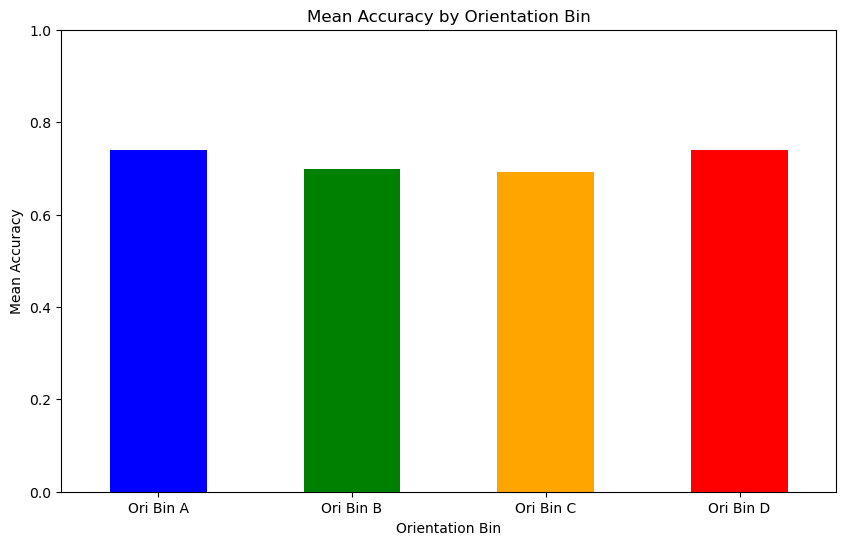

F-statistic: 13.060045526840465
P-value: 1.6247138447906428e-08
The p-value is significant, indicating differences between at least two groups.


In [43]:
## Could also do the same and compare the four orientations per quadrant

# mean_per_ori

# # orientations closest to the cardinal axes
# orientation_subset_A = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]
# orientation_subset_B = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]
# orientation_subset_C = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]
# orientation_subset_D = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]



# Define the orientation bins and labels
orientation_bins = {
    11.25: 'Ori Bin A', 33.75: 'Ori Bin B', 56.25: 'Ori Bin C', 78.75: 'Ori Bin D',
    101.25: 'Ori Bin A', 123.75: 'Ori Bin B', 146.25: 'Ori Bin C', 168.75: 'Ori Bin D',
    191.25: 'Ori Bin A', 213.75: 'Ori Bin B', 236.25: 'Ori Bin C', 258.75: 'Ori Bin D',
    281.25: 'Ori Bin A', 303.75: 'Ori Bin B', 326.25: 'Ori Bin C', 348.75: 'Ori Bin D'
}

# Create a new column with bin labels
df['Orientation_Bin'] = df['object_cued_rot'].map(orientation_bins)

print(df)

## Visualising the data

# Calculate mean accuracy for each bin
mean_accuracies = df.groupby('Orientation_Bin')['acc_trial_concrete_cued'].mean()

# Create a bar plot using matplotlib
plt.figure(figsize=(10, 6))
mean_accuracies.plot(kind='bar', color=['blue', 'green', 'orange', 'red'])
plt.title("Mean Accuracy by Orientation Bin")
plt.xlabel("Orientation Bin")
plt.ylabel("Mean Accuracy")
plt.ylim(0, 1)  # Set y-axis limits to match the range of accuracy values
plt.xticks(rotation=0)
plt.show()

## check if assumptions of ANOVA are met!!!


# Perform ANOVA
anova_results = df.groupby('Orientation_Bin')['acc_trial_concrete_cued'].apply(list)
f_statistic, p_value = f_oneway(*anova_results)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

# Interpret the results
alpha = 0.05
if p_value < alpha:
    print("The p-value is significant, indicating differences between at least two groups.")
else:
    print("The p-value is not significant, indicating no significant differences between groups.")

## could then also insert asterix whereever the data is significantly different

In [44]:
## check if assumptions of ANOVA are met!!!

## Mean accuracy by condition, oneway ANOVA
# does all three conditions in one and groups them by 'items_presented' which is the condition (can add .values at the end if I want only the answer values)
mean_cond = df.groupby('items_presented')['acc_trial_concrete_cued'].mean()
print(mean_cond)
mean_acc = df['acc_trial_concrete_cued'].mean()
print(mean_acc)


acc_cond1 = df.loc[df['items_presented'] == 1, 'acc_trial_concrete_cued']
acc_cond2 = df.loc[df['items_presented'] == 2, 'acc_trial_concrete_cued']
acc_cond3 = df.loc[df['items_presented'] == 3, 'acc_trial_concrete_cued']

# Perform one-way ANOVA
f_statistic, p_value = f_oneway(acc_cond1, acc_cond2, acc_cond3)

# Define the significance level (alpha)
alpha = 0.05

# Print the ANOVA results
print("ANOVA Results:")
print("F-statistic:", f_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The one-way ANOVA indicates a significant difference among the three conditions.")
else:
    print("The one-way ANOVA does not indicate a significant difference among the three conditions.")




items_presented
1    0.798491
2    0.696121
3    0.658585
Name: acc_trial_concrete_cued, dtype: float64
0.7177322796934866
ANOVA Results:
F-statistic: 140.45613292238338
p-value: 3.2210875663318e-61
The one-way ANOVA indicates a significant difference among the three conditions.


In [45]:
## Upside down vs upright accuracy

# these give a boolean value (True/False)

#ud = (ud <= 270 and ud >= 90)
upside_down = (df['object_test_rot_cued'] < 270) & (df['object_test_rot_cued'] > 90)
upright = (df['object_test_rot_cued'] < 90) | (df['object_test_rot_cued'] > 270)
#upside_down = df['object_test_rot_cued'] ('object_test_rot_cued' <= 270) and ('object_test_rot_cued' >= 90)
# could probably do with only one variable and just check wether its true or false
# 180° is not the upright position necessarily, where does the circle start?
#upright = df['object_test_rot_cued'] == ud = (ud <= 270 and ud >= 90)

# might have to be upright= true or something

mean_upside_down = df.loc[upside_down, 'acc_trial_concrete_cued'].mean()
mean_upright = df.loc[upright, 'acc_trial_concrete_cued'].mean()
print(mean_upright)
print(mean_upside_down)


# Perform two-sample independent t-test
t_statistic, p_value = ttest_ind(upside_down, upright)

# Define the significance level (alpha)
alpha = 0.05

# Print the t-test results
print("T-Test Results:")
print("T-statistic:", t_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between upright and upside-down probe items.")
else:
    print("The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.")



0.7319686935580976
0.7036551970472675
T-Test Results:
T-statistic: 1.0285525549030072
p-value: 0.30369742969070557
The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.


In [46]:
# Mnemonic distance + accuracy

block_number
1     0.674330
2     0.663793
3     0.691571
4     0.700192
5     0.723180
6     0.697318
7     0.736590
8     0.760536
9     0.702107
10    0.750000
11    0.721264
12    0.739464
13    0.727969
14    0.726054
15    0.734674
16    0.734674
Name: acc_trial_concrete_cued, dtype: float64


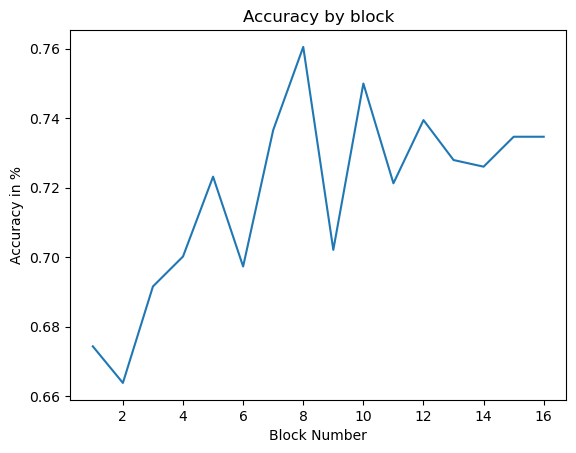

In [47]:
# Accuraccy over time (block by block, do they get better or worse)
# plots using matplotlib
# THIS DOES NOT SEEM TO WORK

#image = plt.imshow(mean_block_allp) #-> heatmap

# ave_plot = matplotlib.pyplot.plot(ave_inflammation) -> general x/y plot
mean_block_allp = df.groupby('block_number')['acc_trial_concrete_cued'].mean()
print(mean_block_allp)
#df_sorted = df.sort_values(by='trial')
#print(df_sorted)
acc_by_block = plt.plot(mean_block_allp)
plt.xlabel('Block Number')  # Set the label for the x-axis
plt.ylabel('Accuracy in %')  # Set the label for the y-axis
plt.title('Accuracy by block')  # Set the title for the plot
plt.show()  # Display the plot

### Add Anova to test if they significantly got better over time


## General Statistics

In [48]:
#Statistics??

# Calculate the standard deviation
#std_dev = df['column_name'].std()
# Calculate the standard deviation across the DataFrame
#std_dev = df.std()

## Circular Stuff

In [49]:
# # Make a column with 1 for clockwise and 0 for anticlockwise

# ### this gives me a column whose content is an object while I need it to be an integer to work on it??

# #if accuracy is True:
    
# #condition that would need to be true: wether the button press was clockwise or anticlockwise
# # if the rot of the tested item's orginal orienation minus the item's final test rotation is positive the accurate rotation would be anticlockwise

# df['correct_rot_response'] = df['object_cued_rot'] - df['object_test_rot_cued']
# #what is the following line?
# df['button_press_clockwise'] = ''
# # Clockwise rotation = 1
# # if the correct response is clockwise and the person was correct -> clockwise button press
# df.loc[(df['correct_rot_response'] > 0) & (df['acc_trial_concrete_cued'] > 0), 'button_press_clockwise'] = 1
# # if the correct response is clockwise and the person was not correct -> anticlockwise button press
# df.loc[(df['correct_rot_response'] > 0) & (df['acc_trial_concrete_cued'] == 0), 'button_press_clockwise'] = 0
# # if the correct response is anticlockwise and the person was correct -> anticlockwise button press
# df.loc[(df['correct_rot_response'] < 0) & (df['acc_trial_concrete_cued'] > 0), 'button_press_clockwise'] = 0
# # if the correct response is anticlockwise and the person was not correct -> clockwise button press
# df.loc[(df['correct_rot_response'] < 0) & (df['acc_trial_concrete_cued'] == 0), 'button_press_clockwise'] = 1

# # maybe need to make that new column into an integer column here, and not underneath when calculating the mean

# # Convert 'button_press_clockwise' to integer dtype
# df['button_press_clockwise'] = df['button_press_clockwise'].astype(int)

# print(df['button_press_clockwise'].dtype)


In [50]:
# The following code is  the same as the one above just simpler and without the need to convert the new column to integer at the end:

# There are no NANs in the button press column. What happens when no button was pressed? Probably they just get an inaccurate but this would not be able to ee in the data, without the trigger there would be no way of knowing whether it was inaccurate because no button was pressed or even though a button was pressed

## !! Still check if the actual column at the end is correct, then delete block above
# put these extra columns for the dataframe at the start to make it more easy to read?

# Calculate 'correct_rot_response'
df['correct_rot_response'] = df['object_cued_rot'] - df['object_test_rot_cued']

# Adding the new column with 0 and 1 values based on conditions
df['button_press_clockwise'] = 0  # Initialize with 0
# if the correct response is clockwise and the person was correct -> clockwise button press
df.loc[(df['correct_rot_response'] > 0) & (df['acc_trial_concrete_cued'] > 0), 'button_press_clockwise'] = 1
# if the correct response is anticlockwise and the person was not correct -> clockwise button press
df.loc[(df['correct_rot_response'] < 0) & (df['acc_trial_concrete_cued'] == 0), 'button_press_clockwise'] = 1

print(df['button_press_clockwise'].dtype)

columns = df.columns
column_names = df.columns.tolist()


int64


the mean of all button presses is: 0.49952107279693486
this is the mbp_per_con: items_presented
1    0.508082
2    0.502694
3    0.487787
Name: button_press_clockwise, dtype: float64
[0.54442344 0.44572526 0.40610105 0.39173228 0.54748062 0.4743833
 0.42253521 0.36103152 0.6230916  0.57979226 0.52266152 0.50425733
 0.64347826 0.58317215 0.53595398 0.40524781]
[0.83811475 0.29298246 0.68400771 0.20881226 0.59692898 0.21780303
 0.61764706 0.16403162 0.75881262 0.31643002 0.652      0.31407942
 0.6026616  0.24675325 0.58901515 0.12909441 0.82395644 0.40040241
 0.77631579 0.38140417 0.71342685 0.34572491 0.6990991  0.28884462
 0.85326087 0.40372671 0.75686275 0.41412214 0.73764259 0.33075435
 0.69556452 0.13508443]


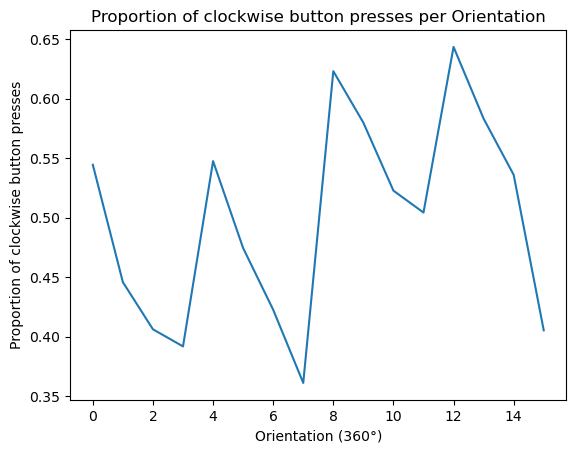

In [51]:
# mean clockwise proportion of all button presses
mean_button_press = df['button_press_clockwise'].mean()
print("the mean of all button presses is:", mean_button_press)

# mean button press per condition (do I already have that somewhere else?)
mbp_per_con = df.groupby('items_presented')['button_press_clockwise'].mean()
print("this is the mbp_per_con:", mbp_per_con)

# mean button press per rotation/ori
mean_rot_button_press = df.groupby('object_cued_rot')['button_press_clockwise'].mean().values
print(mean_rot_button_press)

#Does it make a difference when sorting this over the orientations of testobjects? Probably shouldnt --- !!! nope not the same for some reason 63 values?!?!?
mean_rot_button_press_testobject = df.groupby('object_test_rot_cued')['button_press_clockwise'].mean().values
print(mean_rot_button_press_testobject)

# this is the same data as visualised in the polar plot and should probably be removed
plt.plot(mean_rot_button_press)

plt.xlabel('Orientation (360°)')  # Set the label for the x-axis
plt.ylabel('Proportion of clockwise button presses')  # Set the label for the y-axis
plt.title('Proportion of clockwise button presses per Orientation')  # Set the title for the plot
plt.show()  

## Code stops here when running all



## Cardinal Repulsion Bias Plot (?)
For the polar plot I can either: plt.axes(projection='polar'), plt.polar() or fig = plt.figure() + ax = fig.add_subplot(111, projection='polar')

I think I started the following bullet points when simultaneosly reading the Memoreye paper
Calculating whether
1) a repulsion bias occured (bias away from the cardinal axes)
2)

spacing_rad1 [0.19634954 0.58904862 0.9817477  1.37444679 1.76714587 2.15984495
 2.55254403 2.94524311 3.33794219 3.73064128 4.12334036 4.51603944
 4.90873852 5.3014376  5.69413668 6.08683577]
spacing_rad2 [0.19634954 0.58904862 0.9817477  1.37444679 1.76714587 2.15984495
 2.55254403 2.94524311 3.33794219 3.73064128 4.12334036 4.51603944
 4.90873852 5.3014376  5.69413668 6.08683577 0.19634954]
[0.00950198 0.00777937 0.0070878  0.00683702 0.00955534 0.00827955
 0.00737463 0.00630119 0.010875   0.01011928 0.00912216 0.00880095
 0.01123081 0.01017827 0.00935416 0.00707291]
MBP1: [0.5172413793103449, 0.46551724137931033, 0.4281609195402299, 0.3850574712643678, 0.5747126436781609, 0.4339080459770115, 0.4109195402298851, 0.45689655172413796, 0.6436781609195402, 0.5660919540229885, 0.5431034482758621, 0.514367816091954, 0.632183908045977, 0.5833333333333334, 0.5402298850574713, 0.4339080459770115]
MBP2: [0.5702005730659025, 0.46107784431137727, 0.40166204986149584, 0.4152046783625731, 0.55384

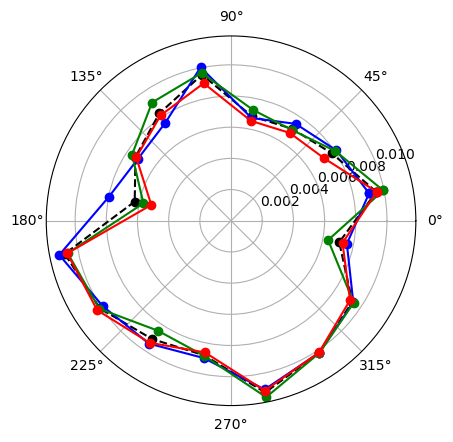

In [52]:


# spacing is what is usually called theta in the polar plots. not sure if this is correct or just a butched way that works, 
# could also be coded using np.arange of divisions of pi, which is more common practice but harder to read
spacing = np.arange(11.25, 360, 22.5)
spacing_rad = np.radians(spacing)
print("spacing_rad1", spacing_rad)
spacing_rad = np.append(spacing_rad, spacing_rad[0])
print("spacing_rad2", spacing_rad)

# mbp = mean button press
mbp_rad = np.radians(mean_rot_button_press)
print(mbp_rad)


# the following line returns the mean button press proportions for all three conditions -- need to somehow but them in individual 
# variables to then transform them into radians to then use them 

## !!!! This is wrong, I am using data at the moment that is a single data point while I actually need 16 data points 
# for every orientation (but also per condition per button press) -> I need data looking like mean_rot_button_press !!!!!!
# !!!!! use the code that I used to make mean_rot_button_press:


#### mean_button_press = df['button_press_clockwise'].mean()
#### print("the mean of all button presses is:", mean_button_press)

#### mean_rot_button_press = df.groupby('object_cued_rot')['button_press_clockwise'].mean().values
#### print(mean_rot_button_press)

# seperate object_cued_rot per condition first and then group the button press clockwise dependingly?

# this gives me the mean per condition, also interesting but I first need the button press mean per orientation?

# df.sort_values returns a new dataframe: that might be useful


mbp_df = df.groupby(by=['object_cued_rot', 'items_presented'])['button_press_clockwise'].mean()
#print(mbp_df)
#-> this output looks right but looking at the variable mbp_df in the data viewer looks weird
# -> this returns a dataframe called mbp_df that is the same size as df but is sorted by object_cued_rot and within each object_cued_rot it is then sorted by items_presented

# seperate by con
mbp1 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 1].tolist()
mbp1_rad = np.radians(mbp1)
mbp2 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 2].tolist()
mbp2_rad = np.radians(mbp2)
mbp3 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 3].tolist()
mbp3_rad = np.radians(mbp3)

print("MBP1:", mbp1)
print("MBP2:", mbp2)
print("MBP3:", mbp3)

# Create the polar plot
fig = plt.figure()
# maybe change the following line to plt.axes(projection='polar')
ax = fig.add_subplot(111, projection='polar')

#Repeating the last data point to make it a full circle
mbp_rad = np.append(mbp_rad, mbp_rad[0])
mbp1_rad = np.append(mbp1_rad, mbp1_rad[0])
mbp2_rad = np.append(mbp2_rad, mbp2_rad[0])
mbp3_rad = np.append(mbp3_rad, mbp3_rad[0])

# Plot the data for the general mbp
ax.plot(spacing_rad, mbp_rad, 'ko--')

# Plot the data for the three conditions individually
ax.plot(spacing_rad, mbp1_rad, 'bo-')
ax.plot(spacing_rad, mbp2_rad, 'go-')
ax.plot(spacing_rad, mbp3_rad, 'ro-')

# Set plot attributes (-> labels and shit)

plt.legend
# Show the plot
plt.show()

## ANOVA for cardinal repulsion effect (?)

In [53]:
# This is probably not what I actually want 

# Perform one-way ANOVA
# The resulting data is every instance of the button_press_clockwise where "items_presented" is one
# however the three resulting variables are not the same size (length = 526, 531 & 528), Why?
# There are no NANs in the button presses (see above)
load_1_data = df[df['items_presented'] == 1]['button_press_clockwise']
load_2_data = df[df['items_presented'] == 2]['button_press_clockwise']
load_3_data = df[df['items_presented'] == 3]['button_press_clockwise']

# Note: f_oneway performs a one-way ANOVA on multiple samples
#returns two variables called statistic and p_value
f_statistic, p_value = f_oneway(load_1_data, load_2_data, load_3_data)#

# should I also (or even do this first) calculate whether the individual conditions are significantly different from the general mean
# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
print("ANOVA Results:")
print("F-statistic:", f_statistic)
print("p-value:", p_value)

if p_value < alpha:
    print("The ANOVA test indicates a significant difference among the load conditions.")
else:
    print("The ANOVA test does not indicate a significant difference among the load conditions.")



ANOVA Results:
F-statistic: 2.4617320540841874
p-value: 0.08531804789831555
The ANOVA test does not indicate a significant difference among the load conditions.
